In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import fastf1
import numpy as np

In [3]:
# Create the cache directory if it doesn't exist
cache_dir = os.path.expanduser('~/fastf1_cache')  # Expand ~ to full home directory path
os.makedirs(cache_dir, exist_ok=True) 

In [4]:
# Configure cache
fastf1.Cache.enable_cache(cache_dir) 

In [5]:
# Load session
session = fastf1.get_session(2023, 'Azerbaijan', 'R')
session.load()

core           INFO 	Loading data for Azerbaijan Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['11', '1', '16', '14', '55', '44', '18', '63', '4', '22', '81', '23', '20', '10', '31', '2', '27', '77', '24', '21']


### LAPS

In [6]:
# Get laps for a driver
driver_laps = session.laps.pick_drivers('55').pick_quicklaps()

In [7]:
# Display lap time statistics
print(f"Total laps: {len(driver_laps)}")
print(f"Fastest lap: {driver_laps['LapTime'].min()}")
print(f"Average lap time: {driver_laps['LapTime'].mean()}")

# Show compound usage
compound_usage = driver_laps.groupby('Compound').size()
print(f"\nCompound usage:\n{compound_usage}")

Total laps: 47
Fastest lap: 0 days 00:01:45.175000
Average lap time: 0 days 00:01:46.722361702

Compound usage:
Compound
HARD      38
MEDIUM     9
dtype: int64


In [8]:
# Enable FastF1's plotting features
from fastf1 import plotting
plotting.setup_mpl(
    mpl_timedelta_support=True,  # Enable timedelta formatting
    color_scheme='fastf1'        # Use FastF1 dark color scheme
)

In [9]:
ver_laps = session.laps.pick_drivers('VER')
ham_laps = session.laps.pick_drivers('HAM')
avg_ver = ver_laps['LapTime'].median()
avg_ham = ham_laps['LapTime'].median()

In [10]:
print(avg_ver)

0 days 00:01:45.497500


In [11]:
for index, lap in ver_laps.iterlaps():
    if lap['LapTime'] == avg_ver:
        ver_median_lap = lap

In [12]:
import fastf1
import pandas as pd

session = fastf1.get_session(2024, 'Monza', 'Q')
session.load()

# Get fastest lap for each driver
fastest_laps = session.laps[session.laps['LapTime'].notna()].loc[session.laps.groupby('Driver')['LapTime'].idxmin()]

# Sort by lap time
fastest_laps = fastest_laps.sort_values('LapTime')

print("Top 10 Qualifying Results:")
for idx, (driver, lap) in enumerate(fastest_laps.head(10).iterrows(), 1):
    print(f"{idx:2d}. {lap['Driver']:3s} - {lap['LapTime']} ({lap['Team']})")

core           INFO 	Loading data for Italian Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['4', '81', '63', '16', '55', '44', '1', '11', '23', '27', '14', '3', '20', '10', '31', '22', '18', '43', '77', '24']


Top 10 Qualifying Results:
 1. NOR - 0 days 00:01:19.327000 (McLaren)
 2. PIA - 0 days 00:01:19.436000 (McLaren)
 3. RUS - 0 days 00:01:19.440000 (Mercedes)
 4. LEC - 0 days 00:01:19.461000 (Ferrari)
 5. SAI - 0 days 00:01:19.467000 (Ferrari)
 6. HAM - 0 days 00:01:19.513000 (Mercedes)
 7. VER - 0 days 00:01:19.662000 (Red Bull Racing)
 8. PER - 0 days 00:01:20.062000 (Red Bull Racing)
 9. ALB - 0 days 00:01:20.299000 (Williams)
10. HUL - 0 days 00:01:20.339000 (Haas F1 Team)


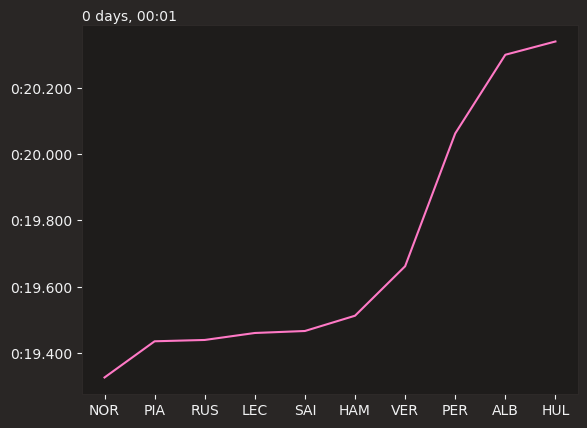

In [17]:
drivers = fastest_laps['Driver'].head(10)
laps = fastest_laps['LapTime'].head(10)
plt.plot(drivers, laps)

In [39]:
teams = {}
for index,lap in fastest_laps.iterrows():
    team=lap["Team"]
    if team not in teams:
        teams[team] = [str(lap["LapTime"])]
    else:
        teams[team].append(str(lap["LapTime"]))
print(teams)  

{'McLaren': ['0 days 00:01:19.327000', '0 days 00:01:19.436000'], 'Mercedes': ['0 days 00:01:19.440000', '0 days 00:01:19.513000'], 'Ferrari': ['0 days 00:01:19.461000', '0 days 00:01:19.467000'], 'Red Bull Racing': ['0 days 00:01:19.662000', '0 days 00:01:20.062000'], 'Williams': ['0 days 00:01:20.299000', '0 days 00:01:21.061000'], 'Haas F1 Team': ['0 days 00:01:20.339000', '0 days 00:01:20.698000'], 'Aston Martin': ['0 days 00:01:20.421000', '0 days 00:01:21.013000'], 'RB': ['0 days 00:01:20.479000', '0 days 00:01:20.945000'], 'Alpine': ['0 days 00:01:20.738000', '0 days 00:01:20.764000'], 'Kick Sauber': ['0 days 00:01:21.101000', '0 days 00:01:21.445000']}


In [45]:
import datetime
team_averages = {}
for team in teams:
    times=teams[team]
    team_lap_times = pd.to_timedelta(times)
    team_averages[team]=team_lap_times.mean()

Text(0, 0.5, 'Lap Time')

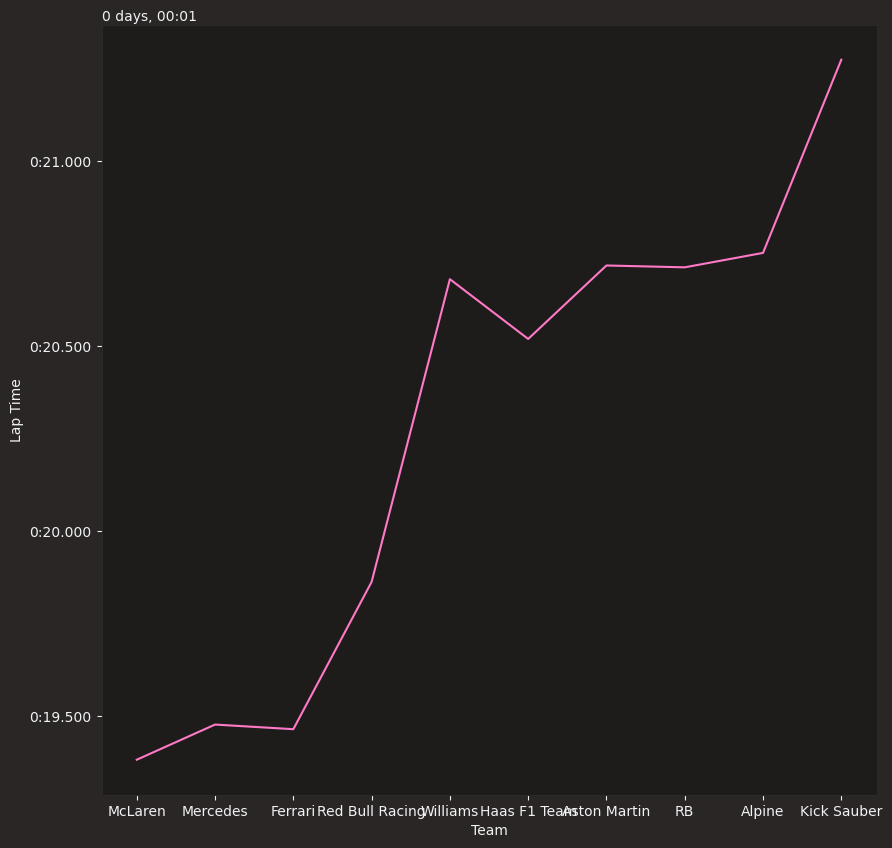

In [48]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(team_averages.keys(), team_averages.values())
ax.set_xlabel('Team')
ax.set_ylabel('Lap Time')

### Performance Analysis

In [5]:
import os 
import fastf1 
# 1. Remove any proxy environment variables 
for var in ['HTTP_PROXY', 'HTTPS_PROXY', 'http_proxy', 'https_proxy', 'ALL_PROXY', 'all_proxy']: os.environ.pop(var, None) 
# 2. Force Python's urllib/requests to ignore system/registry proxies for all hosts 
os.environ['NO_PROXY'] = '*' 
os.environ['no_proxy'] = '*'  

In [1]:
import socket, platform
print("OS:", platform.platform(), "| Hostname:", socket.gethostname())

OS: Linux-6.8.0-1044-aws-x86_64-with-glibc2.31 | Hostname: blue-nbjupyterhub8


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import fastf1
from fastf1 import plotting
import numpy as np

# Create the cache directory if it doesn't exist
cache_dir = os.path.expanduser('~/fastf1_cache')  # Expand ~ to full home directory path
os.makedirs(cache_dir, exist_ok=True) 

# Configure cache
fastf1.Cache.enable_cache(cache_dir)

session = fastf1.get_session(2024, 'Mexico', 'Q')
session.load()
#circuit_info = session.get_circuit_info()

# Enable FastF1's plotting features
plotting.setup_mpl(
    mpl_timedelta_support=True,  # Enable timedelta formatting
    color_scheme='fastf1'        # Use FastF1 dark color scheme
)

# Get fastest lap for each driver
fastest_laps = session.laps[session.laps['LapTime'].notna()].loc[session.laps.groupby('Driver')['LapTime'].idxmin()]

# Sort by lap time
fastest_laps = fastest_laps.sort_values('LapTime')

print("Top 10 Qualifying Results:")
for idx, (driver, lap) in enumerate(fastest_laps.head(10).iterrows(), 1):
    print(f"{idx:2d}. {lap['Driver']:3s} - {lap['LapTime']} ({lap['Team']})")

core           INFO 	Loading data for Mexico City Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['55', '1', '4', '16', '63', '44', '20', '10', '23', '27', '22', '30', '14', '18', '77', '43', '81', '11', '31', '24']


Top 10 Qualifying Results:
 1. SAI - 0 days 00:01:15.946000 (Ferrari)
 2. VER - 0 days 00:01:16.171000 (Red Bull Racing)
 3. NOR - 0 days 00:01:16.260000 (McLaren)
 4. LEC - 0 days 00:01:16.265000 (Ferrari)
 5. RUS - 0 days 00:01:16.356000 (Mercedes)
 6. HAM - 0 days 00:01:16.651000 (Mercedes)
 7. MAG - 0 days 00:01:16.886000 (Haas F1 Team)
 8. GAS - 0 days 00:01:16.892000 (Alpine)
 9. ALB - 0 days 00:01:16.988000 (Williams)
10. HUL - 0 days 00:01:16.995000 (Haas F1 Team)


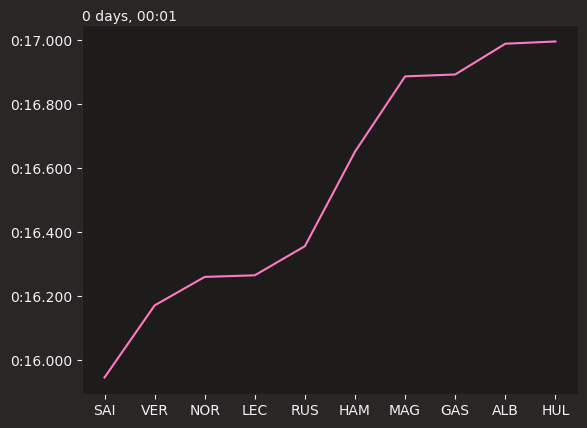

In [4]:
drivers = fastest_laps['Driver'].head(10)
laps = fastest_laps['LapTime'].head(10)
plt.plot(drivers, laps)

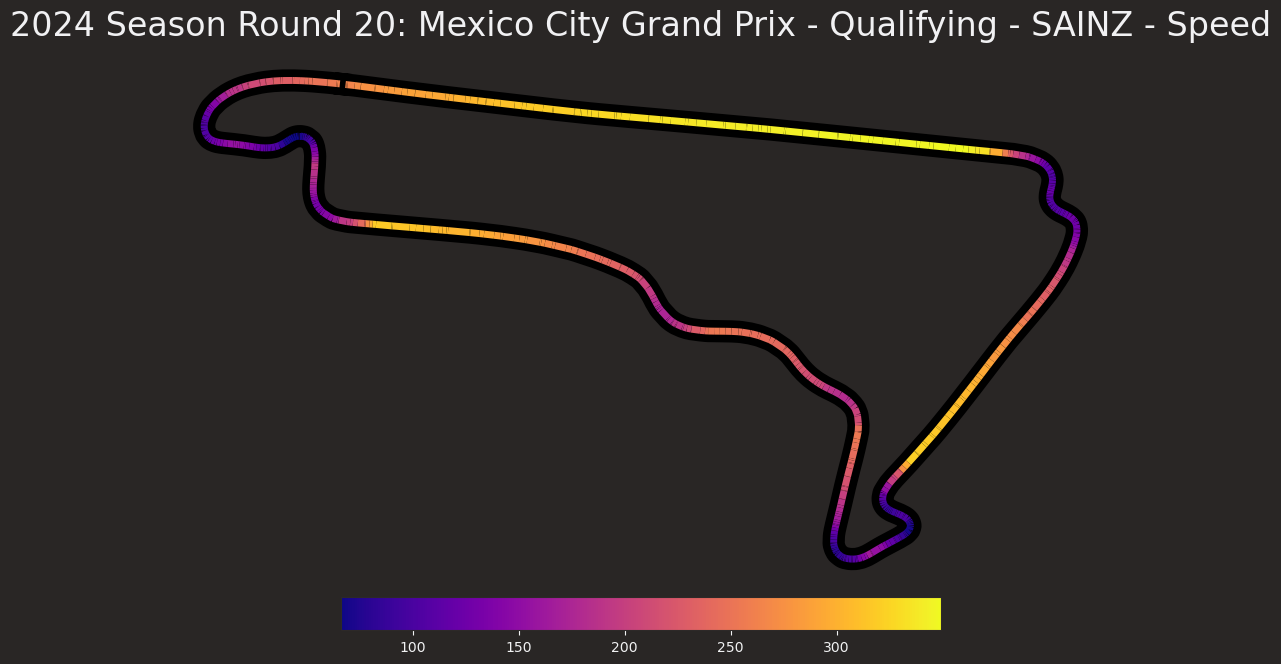

In [61]:
import matplotlib as mpl
from matplotlib.collections import LineCollection

colormap = mpl.cm.plasma
lap = session.laps.pick_drivers('SAI').pick_fastest()

# Get telemetry data
x = lap.telemetry['X']              # values for x-axis
y = lap.telemetry['Y']              # values for y-axis
color = lap.telemetry['Speed']      # value to base color gradient on


points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# We create a plot with title and adjust some setting to make it look good.
fig, ax = plt.subplots(sharex=True, sharey=True, figsize=(12, 6.75))
fig.suptitle(f'{session} - SAINZ - Speed', size=24, y=0.97)

# Adjust margins and turn of axis
plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.12)
ax.axis('off')


# After this, we plot the data itself.
# Create background track line
ax.plot(lap.telemetry['X'], lap.telemetry['Y'],
        color='black', linestyle='-', linewidth=16, zorder=0)

# Create a continuous norm to map from data points to colors
norm = plt.Normalize(color.min(), color.max())
lc = LineCollection(segments, cmap=colormap, norm=norm,
                    linestyle='-', linewidth=5)

# Set the values used for colormapping
lc.set_array(color)
# Merge all line segments together
line = ax.add_collection(lc)

# Finally, we create a color bar as a legend.
cbaxes = fig.add_axes([0.25, 0.05, 0.5, 0.05])
normlegend = mpl.colors.Normalize(vmin=color.min(), vmax=color.max())
legend = mpl.colorbar.ColorbarBase(cbaxes, norm=normlegend, cmap=colormap,
                                   orientation="horizontal")
# Show the plot
plt.show()

### Telemetry

req            INFO 	Using cached data for driver_info


Text(0.5, 1.0, 'Speed Comparison vs Distance')

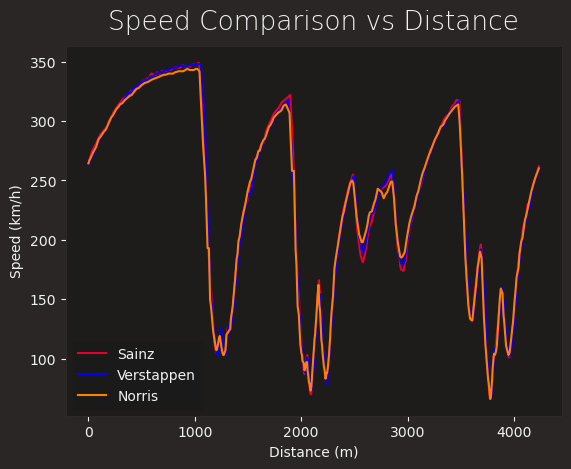

In [5]:
# Get telemetry for top 3: Sainz, Max, Lando 
sainz_lap = session.laps.pick_drivers('SAI').pick_fastest()
max_lap = session.laps.pick_drivers('VER').pick_fastest()
lando_lap = session.laps.pick_drivers('NOR').pick_fastest()

# Get telemetry with distance
sainz_tel = sainz_lap.get_telemetry().add_distance()
max_tel = max_lap.get_telemetry().add_distance()
lando_tel = lando_lap.get_telemetry().add_distance()

# Get color schemes
fer_color = plotting.get_team_color('Ferrari', session=session)
rbr_color = plotting.get_team_color('Red Bull Racing', session=session)
mac_color = plotting.get_team_color('Mclaren', session=session)
# Plot speed vs distance
fig, ax = plt.subplots()
ax.plot(sainz_tel['Distance'], sainz_tel['Speed'], label='Sainz',color=fer_color)
ax.plot(max_tel['Distance'], max_tel['Speed'], label='Verstappen',color=rbr_color)
ax.plot(lando_tel['Distance'], lando_tel['Speed'], label='Norris', color=mac_color)
ax.set_xlabel('Distance (m)')
ax.set_ylabel('Speed (km/h)')
ax.legend()
ax.set_title("Speed Comparison vs Distance")

In [6]:
#Comparing Compound and Sector Times
driver_laps=[sainz_lap, max_lap, lando_lap]
drivers = []
driver_sectors={}
for lap in driver_laps:
    sectors = []
    drivers.append(lap["Driver"])
    driver_name = lap["Driver"]
    sectors.append(lap["Sector1Time"])
    sectors.append(lap["Sector2Time"])
    sectors.append(lap["Sector3Time"])

    driver_sectors[driver_name]=sectors
        

In [7]:
from datetime import timedelta
import seaborn as sns

# Create clean dataframe
records= [
    {'Driver': driver, 'Sector': f'Sector{i+1}', 'Seconds': td.total_seconds()}
    for driver, sectors in driver_sectors.items()
    for i, td in enumerate(sectors)
]
df=pd.DataFrame(records)

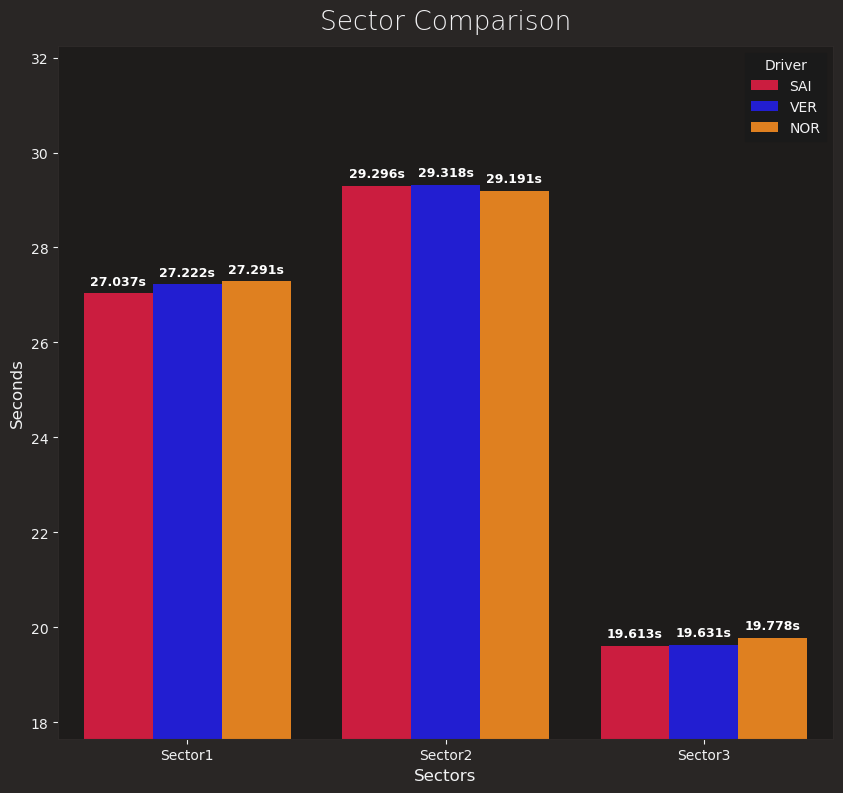

In [8]:
plt.figure(figsize=(10,9))
driver_palette = {'SAI': fer_color, 'VER': rbr_color, 'NOR': mac_color}
ax = sns.barplot(data=df,x='Sector',y='Seconds', hue='Driver', palette=driver_palette)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3fs', padding=4, fontsize=9, weight='bold', color = "white")

min_val=df['Seconds'].min()
max_val=df['Seconds'].max()
ax.set_ylim(bottom=min_val*0.9,top=max_val*1.1)
ax.set_title("Sector Comparison")
ax.set_xlabel("Sectors", fontsize = 12)
ax.set_ylabel("Seconds", fontsize = 12)
ax.legend(title='Driver')

In [9]:
### Throttle Comparison
for lap in driver_laps:
    car_data=lap.get_car_data().add_distance()
    full_throttle_pct = (car_data['Throttle'] >= 99).sum() / len(car_data) * 100
    no_throttle_pct = (car_data['Throttle'] <= 1).sum() / len(car_data) * 100
    partial_throttle = car_data[(car_data['Throttle'] > 0) & (car_data['Throttle'] < 100)]
    driver_name = lap["Driver"]
    print(f"For Driver = {driver_name}:")
    print(f"Full throttle: {full_throttle_pct:.1f}% of lap")
    print(f"Average throttle: {car_data['Throttle'].mean():.1f}%")
    print(f"No Throttle: {no_throttle_pct:.1f}% of lap")

For Driver = SAI:
Full throttle: 49.7% of lap
Average throttle: 64.1%
No Throttle: 20.5% of lap
For Driver = VER:
Full throttle: 51.9% of lap
Average throttle: 62.8%
No Throttle: 26.0% of lap
For Driver = NOR:
Full throttle: 47.6% of lap
Average throttle: 61.0%
No Throttle: 24.8% of lap


In [52]:
### Brake Analysis
def get_braking_zones__and_distances(driver_name,car_data):    
    braking = car_data[car_data['Brake'] == True]

    braking_zones = []
    braking_distances=[]
    current_zone = None
    
    for idx, row in braking.iterrows():
        if current_zone is None:
            current_zone = {'start': row['Distance'], 'end': row['Distance']}
        elif row['Distance'] - current_zone['end'] > 75:
            braking_zones.append(current_zone)
            current_zone = {'start': row['Distance'], 'end': row['Distance']}
        else:
            current_zone['end'] = row['Distance']
    
    if current_zone:
        braking_zones.append(current_zone)
        
    for i, zone in enumerate(braking_zones, 1):
        brake_distance = zone['end']-zone['start']
        braking_distances.append(brake_distance)
        
    print(f"For {driver_name} found {len(braking_zones)} braking zones.")
    print(f"Total braking distance is: {sum(braking_distances):.0f}\n")
    for i, zone in enumerate(braking_zones, 1):
        print(f"  Zone {i}: {zone['start']:.0f}m - {zone['end']:.0f}m")
        print(f"  Zone {i} Total: {braking_distances[i-1]:.0f}m\n")

    return braking_zones, braking_distances

In [53]:
def zone_analysis(car_data,braking_zones):
    zones = {}
    average_speeds = []
    for i in range(len(braking_zones)):
        start = braking_zones[i]['start']
        end = braking_zones[i]['end']
        braking_data = car_data[car_data['Distance'].between(start, end)]
        average_speed = round(braking_data['Speed'].mean(),2)
        average_speeds.append(average_speed)
        #print(f"Average speed for brake zone #{i} is {average_speed} km/h")
        
        zones[f"Zone {i+1}"] = {
            'entry_speed': braking_data.iloc[0]['Speed'],
            'min_speed': braking_data['Speed'].min(),
            'average_speed': round(braking_data['Speed'].mean(),2),
            'exit_speed': braking_data.iloc[-1]['Speed'],
            'max_brake': braking_data['Brake'].mean()
        }
    
    print("\nZone details:")
    for zone, data in list(zones.items()):
        print(f"\n{zone}:")
        print(f"  Entry: {data['entry_speed']:.1f} km/h")
        print(f"  Min Speed: {data['min_speed']:.1f} km/h")
        print(f"  Avg Speed: {data['average_speed']:.1f} km/h")
        print(f"  Exit: {data['exit_speed']:.1f} km/h")
        print(f"  Max brake: {data['max_brake']:.2f}%")
    return average_speeds

In [54]:
brake_speeds = {}
for lap in driver_laps:
    driver_name = lap["Driver"]
    car_data=lap.get_car_data().add_distance()
    
    # Find Brake Zones First
    braking_zones, braking_distances = get_braking_zones__and_distances(driver_name,car_data)
    
    # Now to Brake Speed Comparison
    average_speeds = zone_analysis(car_data,braking_zones)
    brake_speeds[driver_name]=average_speeds
    

For SAI found 8 braking zones.
Total braking distance is: 781

  Zone 1: 1070m - 1319m
  Zone 1 Total: 249m

  Zone 2: 1925m - 2077m
  Zone 2 Total: 152m

  Zone 3: 2167m - 2221m
  Zone 3 Total: 54m

  Zone 4: 2487m - 2556m
  Zone 4 Total: 69m

  Zone 5: 2866m - 2910m
  Zone 5 Total: 44m

  Zone 6: 3488m - 3581m
  Zone 6 Total: 93m

  Zone 7: 3689m - 3763m
  Zone 7 Total: 74m

  Zone 8: 3885m - 3931m
  Zone 8 Total: 46m


Zone details:

Zone 1:
  Entry: 332.0 km/h
  Min Speed: 105.0 km/h
  Avg Speed: 143.7 km/h
  Exit: 126.0 km/h
  Max brake: 0.50%

Zone 2:
  Entry: 273.0 km/h
  Min Speed: 76.0 km/h
  Avg Speed: 126.5 km/h
  Exit: 76.0 km/h
  Max brake: 0.78%

Zone 3:
  Entry: 166.0 km/h
  Min Speed: 91.0 km/h
  Avg Speed: 118.7 km/h
  Exit: 91.0 km/h
  Max brake: 1.00%

Zone 4:
  Entry: 255.0 km/h
  Min Speed: 187.0 km/h
  Avg Speed: 217.0 km/h
  Exit: 187.0 km/h
  Max brake: 1.00%

Zone 5:
  Entry: 247.0 km/h
  Min Speed: 190.0 km/h
  Avg Speed: 215.0 km/h
  Exit: 190.0 km/h
  Max br

In [55]:
from datetime import timedelta
import seaborn as sns

# Create clean dataframe
records= [
    {'Driver': driver, 'Zone': f'Zone{i+1}', 'Speed': td}
    for driver, zones in brake_speeds.items()
    for i, td in enumerate(zones)
]
df=pd.DataFrame(records)

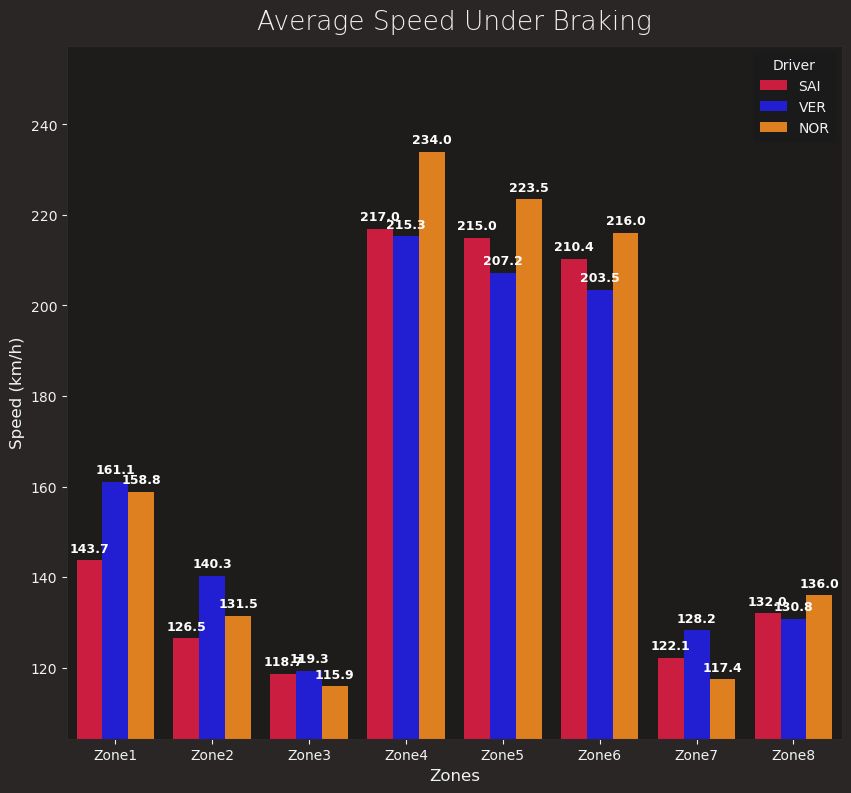

In [56]:
plt.figure(figsize=(10,9))
driver_palette = {'SAI': fer_color, 'VER': rbr_color, 'NOR': mac_color}
ax = sns.barplot(data=df,x='Zone',y='Speed', hue='Driver', palette=driver_palette)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=4, fontsize=9, weight='bold', color = "white")

min_val=df['Speed'].min()
max_val=df['Speed'].max()
ax.set_ylim(bottom=min_val*0.9,top=max_val*1.1)
ax.set_title("Average Speed Under Braking")
ax.set_xlabel("Zones", fontsize = 12)
ax.set_ylabel("Speed (km/h)", fontsize = 12)
ax.legend(title='Driver')

    Corner     Distance  Speed             X            Y
0        1  1204.413991  105.0  11594.242506  -735.513429
1        2  1265.609257  106.0  11581.000000 -1341.000000
2        3  1325.827534  125.0  11987.597664 -1770.312552
3        4  2030.432204   87.0   8884.241591 -7957.580908
4        5  2092.103031   70.0   9242.000000 -8406.000000
5        6  2235.307108   80.0   8042.047934 -8903.337216
6        7  2579.885005  181.0   8202.396345 -5592.058100
7        8  2954.663414  174.0   5127.000000 -3673.000000
8        9  3604.528744  131.0   -554.665450 -1434.995393
9       10  3776.427675   66.0   -916.000000    74.000000
10      11  3951.780932  101.0  -2426.615266   212.710461


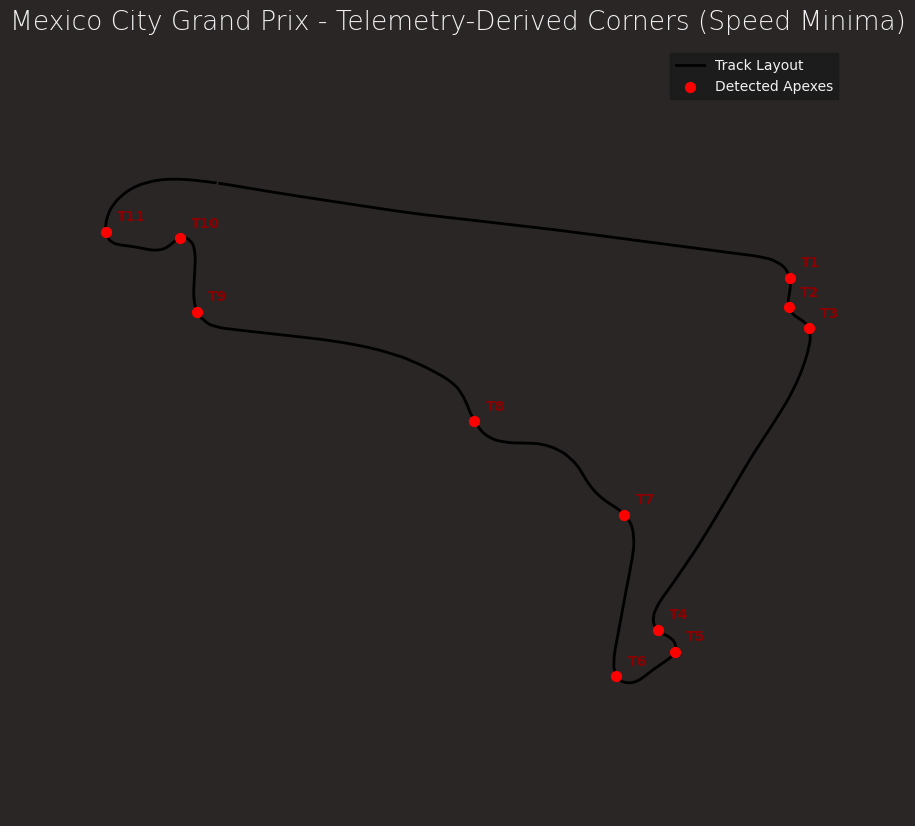

In [57]:
### Creating Corners from Telemetry Data

from scipy.signal import find_peaks

fastest_lap = session.laps.pick_fastest() 
tel = fastest_lap.get_telemetry().add_distance() 

# 2. Find local speed minima (peaks in negative speed) # - prominence=12: The car must slow down by at least 12 km/h to count as a corner # - distance=15: Minimum number of telemetry samples between corners (prevents double-counting chicane apexes) 
inverted_speed = -tel['Speed'].values 
apex_indices, _ = find_peaks(inverted_speed, prominence=2, distance=15) 

# 3. Create a clean DataFrame of the detected corners (just like circuit_info.corners) 
corners_df = tel.iloc[apex_indices][['Distance', 'X', 'Y', 'Speed']].copy() 
corners_df.reset_index(drop=True, inplace=True) 
corners_df['Corner'] = corners_df.index + 1 # Number them 1, 2, 3... 
print(corners_df[['Corner', 'Distance', 'Speed', 'X', 'Y']]) 

# 4. Plot the track and annotate the detected turns 
plt.figure(figsize=(10, 10)) 
plt.plot(tel['X'], tel['Y'], color='black', linewidth=2, label='Track Layout') 
plt.scatter(corners_df['X'], corners_df['Y'], color='red', s=50, zorder=5, label='Detected Apexes') 
for _, row in corners_df.iterrows(): 
    plt.annotate( f"T{int(row['Corner'])}", (row['X'], row['Y']), textcoords="offset points", xytext=(8, 8), fontsize=10, fontweight='bold', color='darkred' ) 
plt.axis('equal') 
plt.axis('off') 
plt.title(f"{session.event['EventName']} - Telemetry-Derived Corners (Speed Minima)") 
plt.legend() 
plt.show()  

In [63]:
# Corner Speed Comparison
corner_base = corners_df[['Corner', 'Distance']]


get_circuit_info() blocked or unavailable. Detecting corners from reference telemetry...


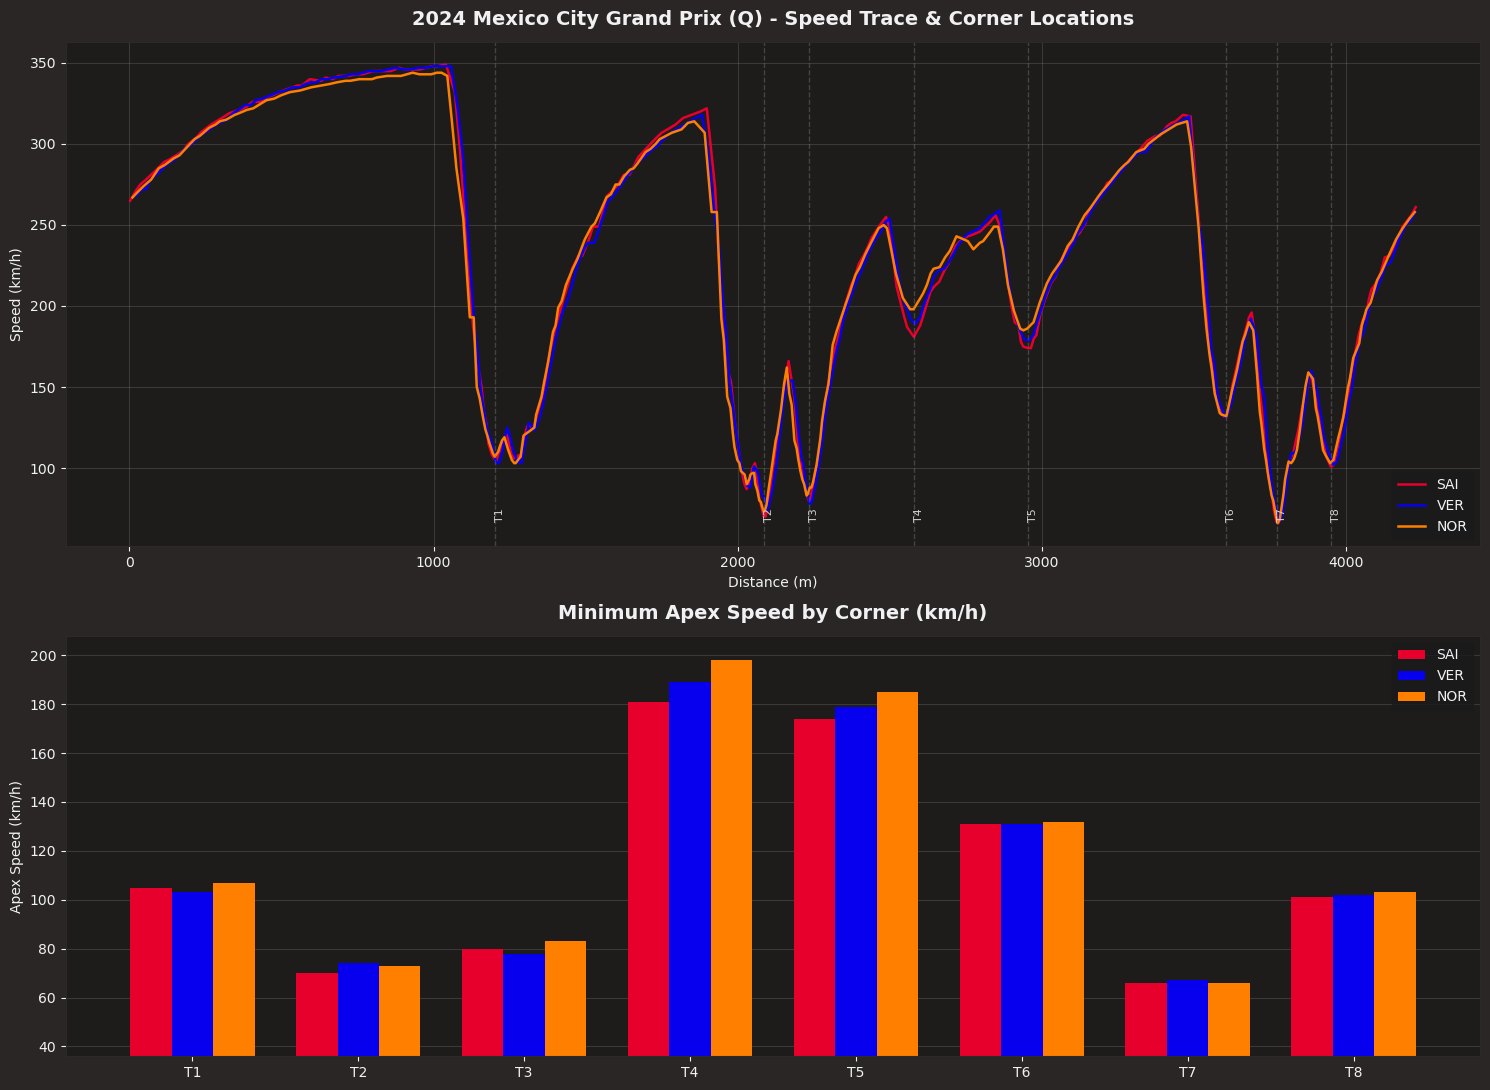


--- Minimum Corner Speeds (km/h) ---
Corner   SAI   VER   NOR
    T1 105.0 103.0 107.0
    T2  70.0  74.0  73.0
    T3  80.0  78.0  83.0
    T4 181.0 189.0 198.0
    T5 174.0 179.0 185.0
    T6 131.0 131.0 132.0
    T7  66.0  67.0  66.0
    T8 101.0 102.0 103.0


In [66]:
# Choose your 3 drivers (3-letter FIA abbreviations)
drivers = ['SAI', 'VER', 'NOR']
year = 2024
session_type = 'Q'
# 2. Extract Fastest Laps & Telemetry for the 3 Drivers
telemetry_dict = {}
for drv in drivers:
    lap = session.laps.pick_drivers(drv).pick_fastest()
    tel = lap.get_car_data().add_distance()
    telemetry_dict[drv] = tel

# 3. Get Corner Locations (Try official API first; fallback to Telemetry detection if blocked)
try:
    circuit_info = session.get_circuit_info()
    corners = circuit_info.corners[['Number', 'Letter', 'Distance']].copy()
    corners['CornerLabel'] = 'T' + corners['Number'].astype(str) + corners['Letter'].fillna('')
    print("Loaded official FIA corners from get_circuit_info().")
except Exception as e:
    print("get_circuit_info() blocked or unavailable. Detecting corners from reference telemetry...")
    ref_tel = telemetry_dict[drivers[0]]
    apex_idx, _ = find_peaks(-ref_tel['Speed'].values, prominence=12, distance=15)
    corners = pd.DataFrame({
        'Distance': ref_tel.iloc[apex_idx]['Distance'].values,
        'CornerLabel': [f"T{i+1}" for i in range(len(apex_idx))]
    })

# 4. Calculate Each Driver's Minimum Apex Speed in a +/- 40m Window Around Each Corner
window_meters = 40
corner_speed_data = []

for _, corner in corners.iterrows():
    c_dist = corner['Distance']
    c_label = corner['CornerLabel']
    
    row_data = {'Corner': c_label, 'Distance': c_dist}
    for drv in drivers:
        tel = telemetry_dict[drv]
        # Slice telemetry within +/- 40m of the corner reference distance
        window = tel[(tel['Distance'] >= c_dist - window_meters) & 
                     (tel['Distance'] <= c_dist + window_meters)]
        
        if not window.empty:
            row_data[drv] = window['Speed'].min()
        else:
            row_data[drv] = np.nan
            
    corner_speed_data.append(row_data)

df_corner_speeds = pd.DataFrame(corner_speed_data)

# Calculate Delta to the slowest/average speed in each corner for better visual contrast
df_corner_speeds['Min_All'] = df_corner_speeds[drivers].min(axis=1)

# 5. Plot Both Views: (Top) Full Speed Trace with Turn Lines | (Bottom) Bar Chart per Corner
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 11), gridspec_kw={'height_ratios': [1.2, 1]})

# Pick distinct colors for each driver using FastF1's color helper
colors = {}
for drv in drivers:
    try:
        colors[drv] = fastf1.plotting.get_driver_color(drv, session=session)
    except Exception:
        colors[drv] = None  # Falls back to default matplotlib cycle if needed

# Fallback if two teammates have the exact same team color
if len(set(colors.values())) < len(drivers):
    fallback_palette = ['#1f77b4', '#ff7f0e', '#2ca02c']
    colors = {drv: fallback_palette[i] for i, drv in enumerate(drivers)}

# --- TOP PLOT: Continuous Speed Trace ---
for drv in drivers:
    tel = telemetry_dict[drv]
    ax1.plot(tel['Distance'], tel['Speed'], label=drv, color=colors[drv], linewidth=1.8)

# Add vertical dotted lines for each corner
for _, corner in df_corner_speeds.iterrows():
    ax1.axvline(x=corner['Distance'], color='gray', linestyle='--', alpha=0.4, linewidth=1)
    ax1.text(corner['Distance'], ax1.get_ylim()[0] + 15, corner['Corner'], 
             rotation=90, verticalalignment='bottom', fontsize=8, color='lightgray')

ax1.set_title(f"{year} {session.event['EventName']} ({session_type}) - Speed Trace & Corner Locations", fontsize=14, fontweight='bold')
ax1.set_xlabel("Distance (m)")
ax1.set_ylabel("Speed (km/h)")
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.2)

# --- BOTTOM PLOT: Grouped Bar Chart of Minimum Apex Speed per Corner ---
x = np.arange(len(df_corner_speeds['Corner']))
width = 0.25  # Width of each bar

for i, drv in enumerate(drivers):
    offset = (i - 1) * width
    bars = ax2.bar(x + offset, df_corner_speeds[drv], width, label=drv, color=colors[drv])

ax2.set_title("Minimum Apex Speed by Corner (km/h)", fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(df_corner_speeds['Corner'])
ax2.set_ylabel("Apex Speed (km/h)")
ax2.set_ylim(bottom=max(0, df_corner_speeds[drivers].min().min() - 30)) # Zoom y-axis to highlight differences
ax2.legend(loc='upper right')
ax2.grid(True, axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

# Print the exact numerical table below the chart
print("\n--- Minimum Corner Speeds (km/h) ---")
print(df_corner_speeds[['Corner'] + drivers].round(1).to_string(index=False))

In [ ]:
# Time Delta Analysis